# Lunar Crater Detection from DEMs: U-Net vs. Classical Baseline

**Project overview (three notebooks)**

1. **Training**: data exploration, preprocessing, U-Net training, model saving; Documentation only (not required to run by supervisor).
2. **Evaluation & crater extraction**: loads trained model, compares two crater-extraction methods on the U-Net masks to choose the best one, builds the classical baseline, compares it against the U-Net, and analyses crater-dating bias; Documentation only (not required to run by supervisor).
3. **Demo**: runs the trained model on a small set of test tiles so the result can be reproduced quickly; this is the one to run.

**Research question:** Can a U-Net detect lunar craters from digital elevation model (DEM) data accurately enough to reproduce the crater size-frequency distribution used for surface dating, and how does its detection completeness as a function of crater diameter bias the derived surface age, compared to a classical, non-learning circle-detection baseline?

# Notebook 1 of 3 - Training 

Produces the trained U-Net model (`crater_unet_best.pt`). This notebook does **not** need to be run by the supervisor.

**Contents of this notebook**

1. Exploratory Data Analysis (EDA)
2. Preprocessing for the U-Net (normalisation, data-loader)
3. U-Net model and training
4. Training curve

### Imports

In [14]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import random, os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

## 1. Exploratory Data Analysis (EDA): DeepMoon

Confirm the data loads, understand its structure, and visualize tile-crater mapping.

### 1.1 Crater table: `train_craters.hdf5`

In [15]:
store = pd.HDFStore('Data/train_craters.hdf5', 'r')
keys = store.keys()
print("Count of imgs:", len(keys))
print("Keys:", keys[0], keys[1], keys[2])

df1 = store[keys[1]]
print("Craters in", keys[1], ":", len(df1))
df1.head()

Count of imgs: 30000
Keys: /img_00000 /img_00001 /img_00002
Craters in /img_00001 : 158


,Diameter (km),Lat,Long,x,y,Diameter (pix)
0,14.372061,8.293652,-155.926564,11.810530,253.690977,9.350264
1,10.046099,8.317680,-150.092753,125.877173,254.746593,6.535854
2,18.844414,8.334572,-146.945852,187.485710,254.015413,12.259916
3,6.418655,8.434751,-149.438026,138.698065,252.433818,4.175889
4,8.448560,8.735085,-155.787675,14.647699,245.087058,5.496517


### 1.2 DEM mosaics & masks: `train_images.hdf5`

In [16]:
f = h5py.File('Data/train_images.hdf5', 'r')

imgs  = f['input_images']
masks = f['target_masks']

print("Total Mosaics:", imgs.shape[0])
print("One Mosaic:", imgs.shape[1:])

i = 0
img0, mask0 = imgs[i], masks[i]
print(f"\nMosaic{i}: Values {img0.min()}-{img0.max()} ({img0.dtype})")
print(f"Mask{i}: Values {round(float(mask0.min()),2)}-{round(float(mask0.max()),2)} ({mask0.dtype})")

Total Mosaics: 30000
One Mosaic: (256, 256)

Mosaic0: Values 0-182 (uint8)
Mask0: Values 0.0-1.0 (float32)


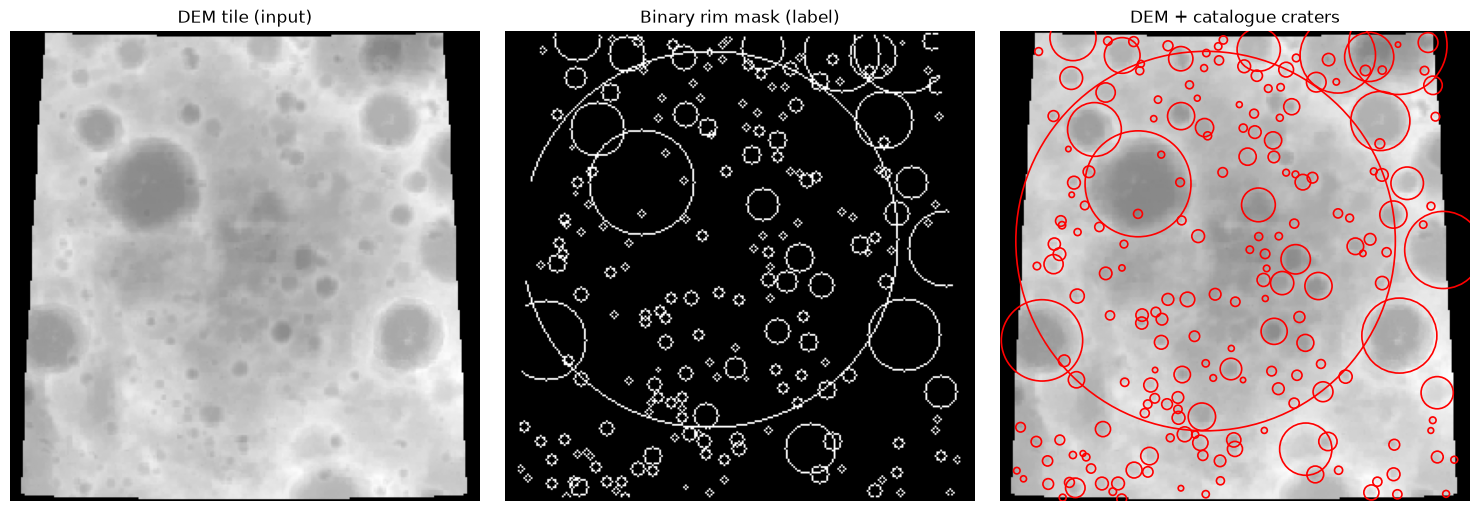

In [17]:
#Plotting one mosaic & mask with crater circles
i = 2
img  = imgs[i]
mask = masks[i]
craters = store[f"/img_{i:05d}"] # craters of the same tile (index i -> id img_xxxxx)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img,  cmap='gray');  ax[0].set_title('DEM tile (input)')
ax[1].imshow(mask, cmap='gray');  ax[1].set_title('Binary rim mask (label)')
ax[2].imshow(img,  cmap='gray');  ax[2].set_title('DEM + catalogue craters')

# draw the craters as red circles on the DEM
for _, c in craters.iterrows():
    ax[2].add_patch(Circle((c['x'], c['y']), c['Diameter (pix)'] / 2,
                           fill=False, color='red', lw=1.2))

for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

### 1.3 Quick check: dev & test data

In [18]:
stored = pd.HDFStore('Data/dev_craters.hdf5', 'r')
print("dev crater tables:", len(stored.keys()))
stored.close()

fd = h5py.File('Data/dev_images.hdf5', 'r')
print("dev mosaics:", fd['input_images'].shape)
fd.close()

dev crater tables: 30000
dev mosaics: (30000, 256, 256)


In [19]:
storet = pd.HDFStore('Data/test_craters.hdf5', 'r')
print("test crater tables:", len(storet.keys()))
storet.close()

ft = h5py.File('Data/test_images.hdf5', 'r')
print("test mosaics:", ft['input_images'].shape)
ft.close()

test crater tables: 30000
test mosaics: (30000, 256, 256)


## 2. Preprocessing for the U-Net

Get the data model-ready: if necessary subsample to a computable size, normalise the DEM to 0,1 and add a channel axis (n, 256, 256, 1).

In [20]:
# how many mosaics to use
N_TRAIN = 30000
N_VAL   = 30000

def load_subset(images_path, n):
    with h5py.File(images_path, 'r') as fh:
        X = fh['input_images'][:n].astype('float32') / 255.0 # DEM 0-255 to 0-1
        Y = fh['target_masks'][:n].astype('float32') # mask already in 0-1
    X = X[..., np.newaxis]   # (n, 256, 256) -> (n, 256, 256, 1)
    Y = Y[..., np.newaxis]
    return X, Y

X_train, Y_train = load_subset('Data/train_images.hdf5', N_TRAIN)
X_val,Y_val = load_subset('Data/dev_images.hdf5', N_VAL)

# to PyTorch tensors, channels first: (N, H, W, C) -> (N, C, H, W)
def to_tensor(X):
    return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()

train_ds = TensorDataset(to_tensor(X_train), to_tensor(Y_train)) #connects input and label
val_ds   = TensorDataset(to_tensor(X_val),   to_tensor(Y_val))

# DataLoaders hand out the batches (batch size 16); shuffle the training data each epoch
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=4, pin_memory=True)

print("train:", X_train.shape, X_train.dtype, "| masks", Y_train.shape)
print("val:", X_val.shape, X_val.dtype, "| masks", Y_val.shape)
print("DEM range after norm:", X_train.min(), "-", X_train.max())
print("mask range:", Y_train.min(), "-", Y_train.max())

print("train:", X_train.shape, "| val:", X_val.shape)
print("train batches:", len(train_loader), "| val batches:", len(val_loader))

train: (30000, 256, 256, 1) float32 | masks (30000, 256, 256, 1)
val: (30000, 256, 256, 1) float32 | masks (30000, 256, 256, 1)
DEM range after norm: 0.0 - 1.0
mask range: 0.0 - 1.0
train: (30000, 256, 256, 1) | val: (30000, 256, 256, 1)
train batches: 1875 | val batches: 1875


## 3. U-Net: Model & Training

Architecture: 4 encoder stages + bottleneck + 4 decoder stages; each stage is one conv block = (Conv → BatchNorm → ReLU) × 2. 
Filters 32 → 64 → 128 → 256 → 512, halving the resolution each stage. Skip connections link encoder to decoder; output is 1 channel + sigmoid.

Training: Dice loss, Adam (lr 1e-3), batch size 16, 50 epochs.

### 3.1 Seed & device

In [21]:
# fix seeds so runs are reproducible
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", device)

device: cuda


### 3.2 The U-Net

In [22]:
# one conv block
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential( # chain of layers saved in self.block
            nn.Conv2d(in_ch,  out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): # worker: run x through this one block
        return self.block(x)

# build the layers & weights (numbers only)
class UNet(nn.Module):
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        self.pool = nn.MaxPool2d(2) #max pooling from 4 pixels
        # encoder: halve size, double filters each stage
        self.e1 = ConvBlock(in_ch,   base)    # 256
        self.e2 = ConvBlock(base,    base*2)  # 128
        self.e3 = ConvBlock(base*2,  base*4)  # 64
        self.e4 = ConvBlock(base*4,  base*8)  # 32
        # bottleneck
        self.b  = ConvBlock(base*8,  base*16) # 16
        # decoder: upsample, then concat the matching encoder features (skip connections)
        self.u4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2); self.d4 = ConvBlock(base*16, base*8)
        self.u3 = nn.ConvTranspose2d(base*8,  base*4, 2, stride=2); self.d3 = ConvBlock(base*8,  base*4)
        self.u2 = nn.ConvTranspose2d(base*4,  base*2, 2, stride=2); self.d2 = ConvBlock(base*4,  base*2)
        self.u1 = nn.ConvTranspose2d(base*2,  base,   2, stride=2); self.d1 = ConvBlock(base*2,  base)
        self.out = nn.Conv2d(base, 1, 1)

# Images flow through the layers
    def forward(self, x): # coordinator: calls the blocks, does pooling/skips itself
        # encoder path, keep each output for the skip connection
        c1 = self.e1(x)
        c2 = self.e2(self.pool(c1))
        c3 = self.e3(self.pool(c2))
        c4 = self.e4(self.pool(c3))
        b  = self.b(self.pool(c4))
        # decoder path: upsample + concat skip + conv
        x = self.d4(torch.cat([self.u4(b), c4], dim=1))
        x = self.d3(torch.cat([self.u3(x), c3], dim=1))
        x = self.d2(torch.cat([self.u2(x), c2], dim=1))
        x = self.d1(torch.cat([self.u1(x), c1], dim=1))
        return torch.sigmoid(self.out(x)) # per-pixel rim probability (0-1)

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

7765409 parameters


### 3.3 Dice loss & metric

In [23]:
# Dice measures overlap of predicted vs. true rings (because of rim-pixel imbalance)
def dice_coef(pred, target, smooth=1.0):
    pred   = pred.reshape(pred.size(0), -1) # (16, 1, 256, 256) to (16, 65536)
    target = target.reshape(target.size(0), -1)
    inter  = (pred * target).sum(dim=1) # sum of "both predict rim" -> (16,)
    union  = pred.sum(dim=1) + target.sum(dim=1) # all rim pixels of both masks 
    return ((2*inter + smooth) / (union + smooth)).mean() # meaning over all 16 images

def dice_loss(pred, target):
    return 1 - dice_coef(pred, target)

### 3.4 Training loop

In [24]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) # optimizes weights
EPOCHS = 50
history = {'train_loss': [], 'val_loss': []} # collect losses for the plot
best_val = float('inf')
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    
    # train:
    model.train() # sets BatchNorm to training-mode
    train_loss = 0.0 # accumulator for losses in one epoch
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad() # delete old gradients
        loss = dice_loss(model(xb), yb) # run U-Net on the batch, compare to truth -> one error number
        loss.backward() # backpropagation (calculating gradient)
        optimizer.step() # applying gradients
        train_loss += loss.item() * xb.size(0)
    train_loss /= len(train_loader.dataset) # mean loss of the epoch
    
    # validate (same like train, just without weight-adapting):
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            val_loss += dice_loss(model(xb), yb).item() * xb.size(0)
    val_loss /= len(val_loader.dataset)
    history['train_loss'].append(train_loss) # store for plotting
    history['val_loss'].append(val_loss)
    print(f"epoch {epoch:2d} | train dice_loss {train_loss:.4f} | val dice_loss {val_loss:.4f} | val dice {1-val_loss:.4f}")
    
    # save weights: latest and best separately (best = lowest val loss)
    torch.save(model.state_dict(), 'crater_unet_latest.pt')
    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), 'crater_unet_best.pt')
        
print(f"\ndone. best epoch: {best_epoch} | val dice_loss {best_val:.4f} (= dice score {1-best_val:.4f})")

epoch  1 | train dice_loss 0.7492 | val dice_loss 0.6763 | val dice 0.3237
epoch  2 | train dice_loss 0.7058 | val dice_loss 0.6508 | val dice 0.3492
epoch  3 | train dice_loss 0.6960 | val dice_loss 0.6777 | val dice 0.3223
epoch  4 | train dice_loss 0.7007 | val dice_loss 0.6426 | val dice 0.3574
epoch  5 | train dice_loss 0.6826 | val dice_loss 0.6502 | val dice 0.3498
epoch  6 | train dice_loss 0.6833 | val dice_loss 0.6473 | val dice 0.3527
epoch  7 | train dice_loss 0.6675 | val dice_loss 0.6430 | val dice 0.3570
epoch  8 | train dice_loss 0.6622 | val dice_loss 0.6192 | val dice 0.3808
epoch  9 | train dice_loss 0.6592 | val dice_loss 0.6405 | val dice 0.3595
epoch 10 | train dice_loss 0.6605 | val dice_loss 0.6248 | val dice 0.3752
epoch 11 | train dice_loss 0.6582 | val dice_loss 0.6113 | val dice 0.3887
epoch 12 | train dice_loss 0.6570 | val dice_loss 0.6305 | val dice 0.3695
epoch 13 | train dice_loss 0.6511 | val dice_loss 0.6102 | val dice 0.3898
epoch 14 | train dice_los

### 3.5 Sanity check

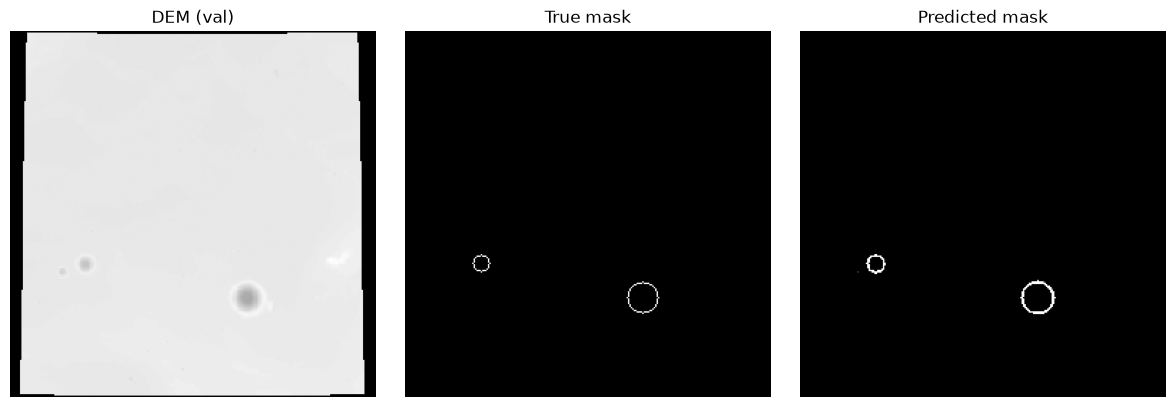

In [25]:
model.eval()
j = 8
with torch.no_grad():
    xb = to_tensor(X_val[j:j+1]).to(device)
    pred = model(xb).cpu().numpy()[0, 0]

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(X_val[j, ..., 0], cmap='gray'); ax[0].set_title('DEM (val)') # input
ax[1].imshow(Y_val[j, ..., 0], cmap='gray'); ax[1].set_title('True mask') # truth
ax[2].imshow(pred,             cmap='gray'); ax[2].set_title('Predicted mask') # prediction
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 4. Training plot

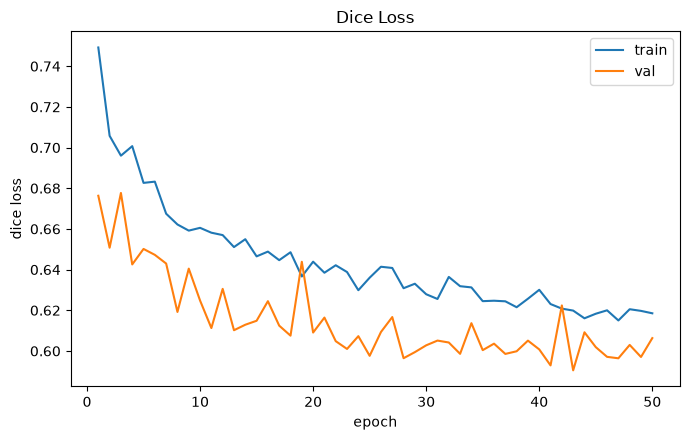

In [26]:
ep = range(1, EPOCHS + 1)
plt.figure(figsize=(7, 4.5))
plt.plot(ep, history['train_loss'], label='train')
plt.plot(ep, history['val_loss'],   label='val')
plt.xlabel('epoch'); plt.ylabel('dice loss'); plt.title('Dice Loss')
plt.legend(); plt.tight_layout(); plt.show()